credit_risk.ipynb — Loan Default Risk Analysis
Author : Aman Raza
Date   : August 2026
Dataset: Credit Risk Dataset (32,581 records)
Source : https://www.kaggle.com/datasets/laotse/credit-risk-dataset
 
Pipeline:
  1. Load & Inspect Data
  2. Data Cleaning & ETL
  3. Exploratory Data Analysis (EDA)
  4. Correlation Analysis
  5. Key Business Insights
  6. Visualisations 
  7. Export cleaned CSV for SQL and Power BI

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

In [2]:
 # ══════════════════════════════════════════════════════════════════
 # 1. LOAD & INSPECT
 # ══════════════════════════════════════════════════════════════════


In [3]:
df = pd.read_csv("credit_risk_dataset.csv")


In [4]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [5]:
df.shape

(32581, 12)

In [6]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [8]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [9]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(165)

In [11]:
df.describe(include='object')

,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


# ══════════════════════════════════════════════════════════════════
# 2. DATA CLEANING & ETL
# ══════════════════════════════════════════════════════════════════

In [12]:
df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())
df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_int_rate"].median())

df.isnull().sum()

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

In [13]:
df = df.drop_duplicates()
df.duplicated().sum()
df.dtypes

person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

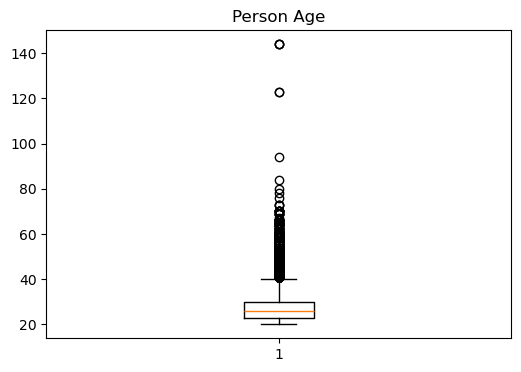

In [14]:
plt.figure(figsize=(6,4))
plt.boxplot(df["person_age"])
plt.title("Person Age")
plt.show()

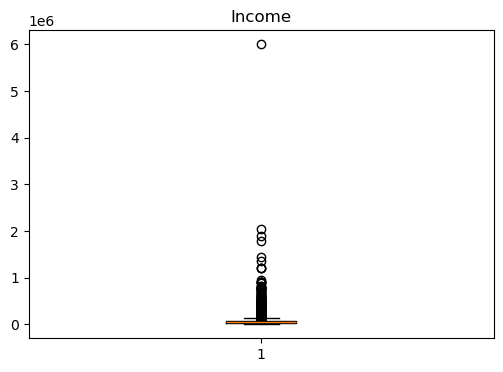

In [15]:
plt.figure(figsize=(6,4))
plt.boxplot(df["person_income"])
plt.title("Income")
plt.show()

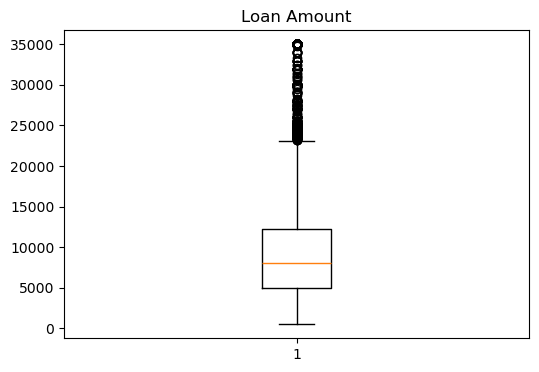

In [16]:
plt.figure(figsize=(6,4))
plt.boxplot(df["loan_amnt"])
plt.title("Loan Amount")
plt.show()

In [17]:
df["person_age"].describe()

count    32416.000000
mean        27.747008
std          6.354100
min         20.000000
25%         23.000000
50%         26.000000
75%         30.000000
max        144.000000
Name: person_age, dtype: float64

In [18]:
df[df["person_age"]>100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,10.99,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


In [19]:
df["person_emp_length"].describe()

count    32416.000000
mean         4.768880
std          4.090411
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max        123.000000
Name: person_emp_length, dtype: float64

In [20]:
df[df["person_emp_length"]>60]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


In [21]:
df["loan_int_rate"].describe()

count    32416.000000
mean        11.014662
std          3.083050
min          5.420000
25%          8.490000
50%         10.990000
75%         13.110000
max         23.220000
Name: loan_int_rate, dtype: float64

In [22]:
df.shape

(32416, 12)

In [23]:
df = df[df["person_age"] <= 100]
df["person_age"].describe()

count    32411.000000
mean        27.730369
std          6.210448
min         20.000000
25%         23.000000
50%         26.000000
75%         30.000000
max         94.000000
Name: person_age, dtype: float64

In [24]:
df = df[df["person_emp_length"] <= 60]
df["person_emp_length"].describe()

count    32409.000000
mean         4.761424
std          3.983757
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max         41.000000
Name: person_emp_length, dtype: float64

In [25]:
df.shape

(32409, 12)

In [26]:
for col in df.select_dtypes(include="object"):
    print("\n",col)
    print(df[col].value_counts())


 person_home_ownership
person_home_ownership
RENT        16374
MORTGAGE    13366
OWN          2563
OTHER         106
Name: count, dtype: int64

 loan_intent
loan_intent
EDUCATION            6409
MEDICAL              6042
VENTURE              5679
PERSONAL             5496
DEBTCONSOLIDATION    5189
HOMEIMPROVEMENT      3594
Name: count, dtype: int64

 loan_grade
loan_grade
A    10702
B    10384
C     6436
D     3619
E      963
F      241
G       64
Name: count, dtype: int64

 cb_person_default_on_file
cb_person_default_on_file
N    26680
Y     5729
Name: count, dtype: int64


In [27]:
df.to_csv("credit_risk_cleaned.csv", index=False)

In [28]:
df["loan_status"].value_counts()

loan_status
0    25321
1     7088
Name: count, dtype: int64

In [29]:
loan_status_pct = df["loan_status"].value_counts(normalize=True) * 100
loan_status_pct

loan_status
0    78.129532
1    21.870468
Name: proportion, dtype: float64

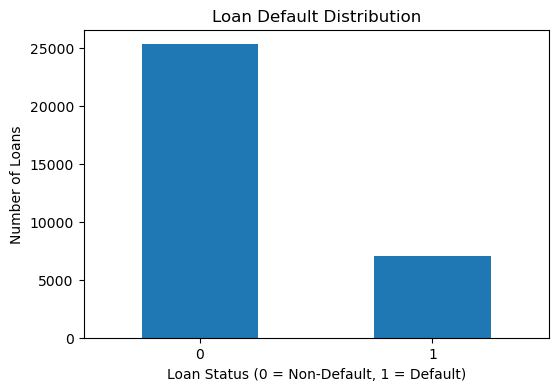

In [30]:
df["loan_status"].value_counts().plot(
    kind="bar",
    figsize=(6,4)
)

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status (0 = Non-Default, 1 = Default)")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.show()

In [31]:
default_summary = pd.DataFrame({
    "Count": df["loan_status"].value_counts(),
    "Percentage": df["loan_status"].value_counts(normalize=True) * 100
})

default_summary

,Count,Percentage
loan_status,,
0,25321,78.129532
1,7088,21.870468


In [32]:
pd.crosstab(
    df["loan_intent"],
    df["loan_status"],
    normalize="index"
) * 100

loan_status,0,1
loan_intent,,
DEBTCONSOLIDATION,71.323955,28.676045
EDUCATION,82.743018,17.256982
HOMEIMPROVEMENT,73.845298,26.154702
MEDICAL,73.237339,26.762661
PERSONAL,80.112809,19.887191
VENTURE,85.138229,14.861771


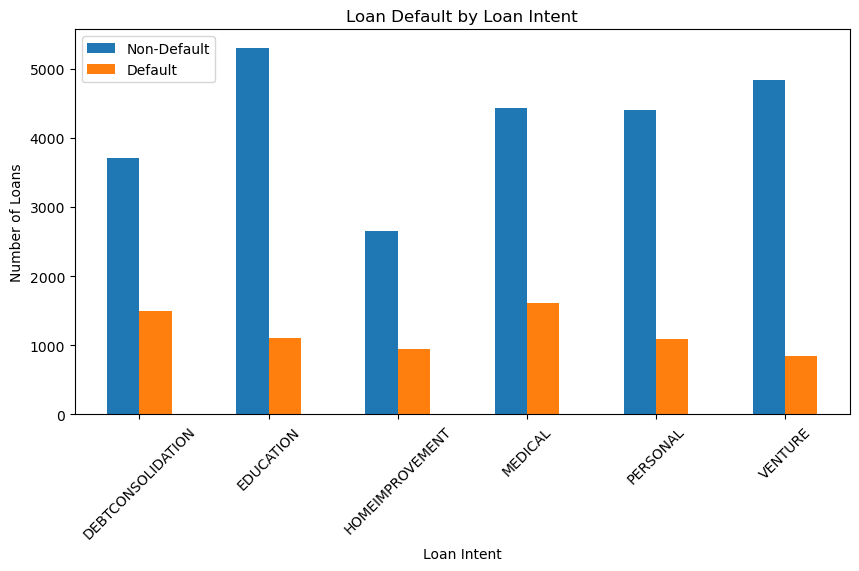

In [33]:
pd.crosstab(
    df["loan_intent"],
    df["loan_status"]
).plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Loan Default by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Number of Loans")
plt.xticks(rotation=45)
plt.legend(["Non-Default", "Default"])
plt.show()

In [34]:
pd.crosstab(
    df["loan_grade"],
    df["loan_status"],
    normalize="index"
) * 100

loan_status,0,1
loan_grade,,
A,90.039245,9.960755
B,83.676810,16.323190
C,79.241765,20.758235
D,40.950539,59.049461
E,35.514019,64.485981
F,29.460581,70.539419
G,1.562500,98.437500


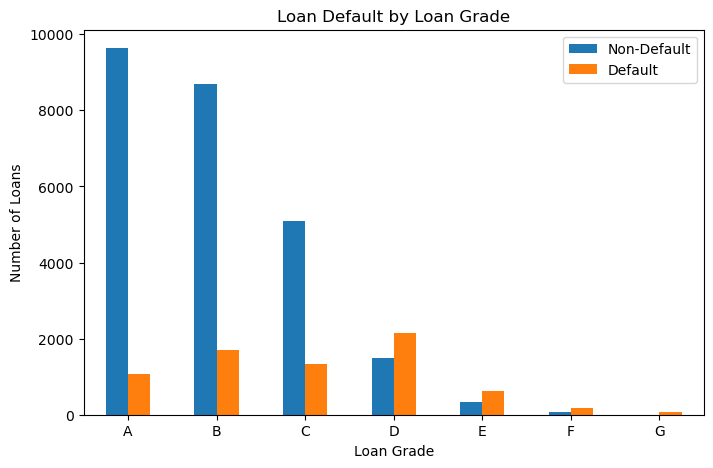

In [35]:
pd.crosstab(
    df["loan_grade"],
    df["loan_status"]
).plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Loan Default by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(["Non-Default", "Default"])
plt.show()